# BBC Headlines: POS Tagging & Named Entity Recognition

A walkthrough of the analysis in `src/analyze.py`. The notebook reuses those functions, so the script and the notebook always agree.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import matplotlib.pyplot as plt
import analyze

plt.rcParams['figure.figsize'] = (7, 4)

## Load data

In [2]:
titles = analyze.load_titles()
print(len(titles), 'unique headlines')
titles.head()

995 unique headlines


0                                Can I refuse to work?
1    'Liz Truss the Brief?' World reacts to UK poli...
2    Rationing energy is nothing new for off-grid c...
3    The hunt for superyachts of sanctioned Russian...
4    Platinum Jubilee: 70 years of the Queen in 70 ...
Name: title, dtype: str

## Clean text

Lowercase → remove stop words → remove punctuation → tokenize → lemmatize. This gives an overall view of the vocabulary. POS and NER below run on the *original* headlines, because cleaning removes the grammatical clues those models need.

In [3]:
cleaned = analyze.clean_titles(titles)
cleaned[['title', 'clean', 'lemmas']].head()

,title,clean,lemmas
0,Can I refuse to work?,refuse work,"[refuse, work]"
1,'Liz Truss the Brief?' World reacts to UK poli...,liz truss brief world reacts uk political turmoil,"[liz, truss, brief, world, reacts, uk, politic..."
2,Rationing energy is nothing new for off-grid c...,rationing energy nothing new offgrid community,"[rationing, energy, nothing, new, offgrid, com..."
3,The hunt for superyachts of sanctioned Russian...,hunt superyachts sanctioned russian oligarchs,"[hunt, superyachts, sanctioned, russian, oliga..."
4,Platinum Jubilee: 70 years of the Queen in 70 ...,platinum jubilee 70 years queen 70 seconds,"[platinum, jubilee, 70, year, queen, 70, second]"


In [4]:
from collections import Counter
pd.DataFrame(Counter(sum(cleaned['lemmas'], [])).most_common(10), columns=['lemma', 'count'])

,lemma,count
0,world,56
1,ukraine,55
2,cup,50
3,england,48
4,2022,46
5,war,41
6,say,38
7,win,36
8,uk,35
9,new,35


## Part-of-speech tagging and named entities

spaCy runs over each headline separately. POS counts use lowercase lemmas of alphabetic tokens; entities keep their original form.

In [5]:
pos, ner = analyze.tag_titles(titles)
pos.head()

,lemma,pos_tag
0,can,AUX
1,i,PRON
2,refuse,VERB
3,to,PART
4,work,VERB


In [6]:
ner.head()

,entity,ner_tag
0,Liz Truss,PERSON
1,UK,GPE
2,superyachts,CARDINAL
3,Russian,NORP
4,70 years,DATE


## Part-of-speech results

Nouns show the topics, verbs the actions headlines favour, adjectives the framing.

In [7]:
nouns = analyze.top_counts(pos, 'pos_tag', 'NOUN')
nouns

,lemma,count
0,war,35
1,year,26
2,woman,25
3,week,19
4,win,18
5,cost,18
6,day,18
7,police,18
8,energy,17
9,record,16


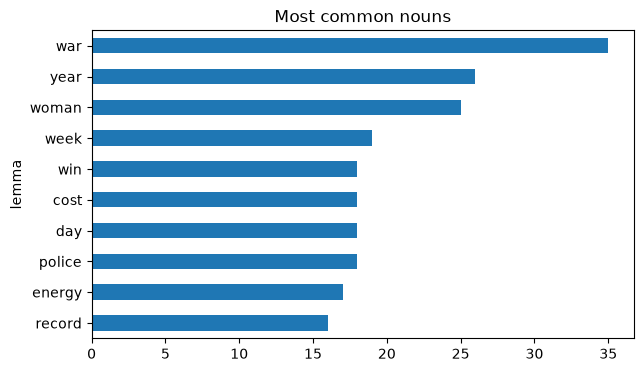

In [8]:
nouns.iloc[::-1].plot.barh(x='lemma', y='count', legend=False, title='Most common nouns')
plt.show()

In [9]:
verbs = analyze.top_counts(pos, 'pos_tag', 'VERB')
verbs

,lemma,count
0,say,40
1,win,23
2,find,20
3,take,19
4,beat,18
5,make,17
6,get,17
7,give,17
8,go,15
9,hit,13


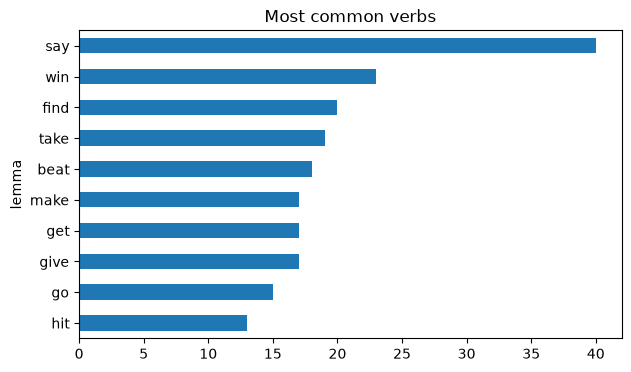

In [10]:
verbs.iloc[::-1].plot.barh(x='lemma', y='count', legend=False, title='Most common verbs')
plt.show()

In [11]:
adjectives = analyze.top_counts(pos, 'pos_tag', 'ADJ')
adjectives

,lemma,count
0,new,31
1,russian,21
2,final,16
3,first,15
4,high,14
5,more,14
6,big,13
7,late,9
8,other,8
9,last,8


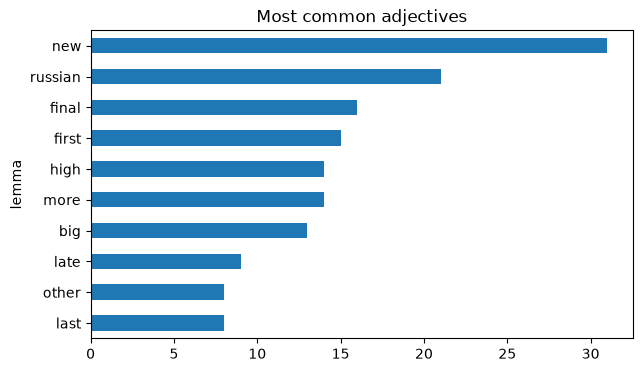

In [12]:
adjectives.iloc[::-1].plot.barh(x='lemma', y='count', legend=False, title='Most common adjectives')
plt.show()

## Named entity results

`PERSON` = people, `GPE` = countries/cities, `ORG` = organisations. The small model makes occasional mistakes on short headlines (e.g. "Covid" as `PERSON`), so treat rankings as indicative.

In [13]:
people = analyze.top_counts(ner, 'ner_tag', 'PERSON')
people

,entity,count
0,Putin,8
1,Liz Truss,6
2,Queen,6
3,Boris Johnson,6
4,Harry,5
5,Covid,5
6,Rishi Sunak,5
7,Emma Raducanu,4
8,Macron,4
9,Zelensky,4


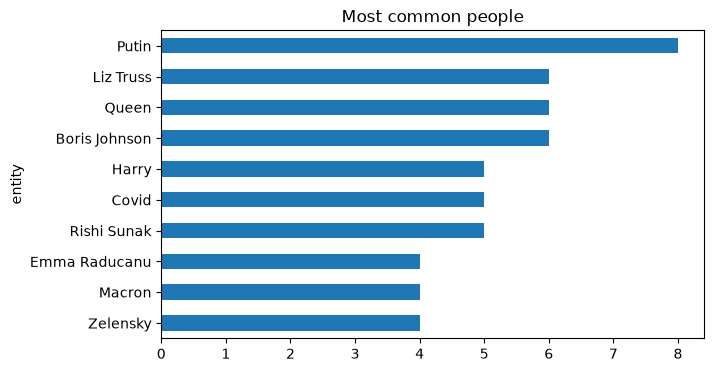

In [14]:
people.iloc[::-1].plot.barh(x='entity', y='count', legend=False, title='Most common people')
plt.show()

In [15]:
places = analyze.top_counts(ner, 'ner_tag', 'GPE')
places

,entity,count
0,Ukraine,55
1,England,37
2,UK,34
3,US,22
4,France,12
5,China,11
6,Russia,10
7,India,9
8,London,8
9,Australia,7


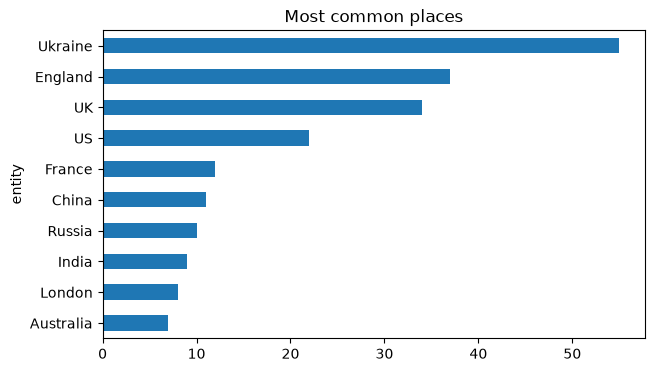

In [16]:
places.iloc[::-1].plot.barh(x='entity', y='count', legend=False, title='Most common places')
plt.show()

In [17]:
organisations = analyze.top_counts(ner, 'ner_tag', 'ORG')
organisations

,entity,count
0,BBC,6
1,Nato,5
2,Liverpool,5
3,Nasa,4
4,NHS,4
5,EU,4
6,Commonwealth Games,4
7,TikTok,4
8,Nicola Bulley,3
9,WSL,3


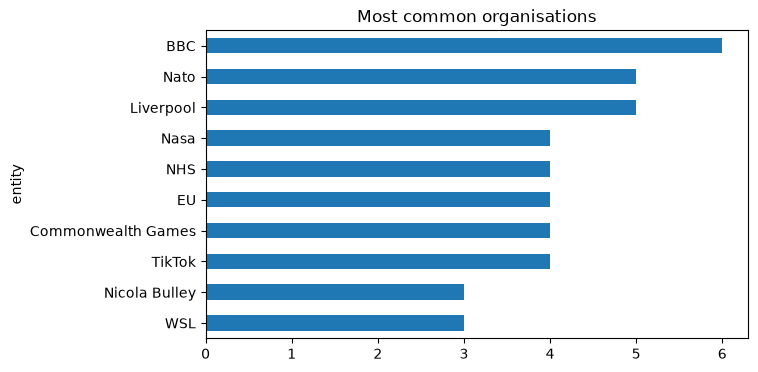

In [18]:
organisations.iloc[::-1].plot.barh(x='entity', y='count', legend=False, title='Most common organisations')
plt.show()